In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")

# input dari Data Preparation: dua kelas (Nomina dan Verba) supaya mudah dilihat sebagai dua sisi garis pemisah
data = pd.read_csv("../data/kbbi_bersih.csv")
data = data[data["kelas_utama"].isin(["Nomina", "Verba"])]

# SVM lambat pada data besar, jadi dipakai 5.000 data latih dan 5.000 data uji
train = data[data["split"] == "train"].sample(5000, random_state=42)
test = data[data["split"] == "test"].sample(5000, random_state=42)
y_train, y_test = train["kelas_utama"], test["kelas_utama"]

vec = TfidfVectorizer(max_features=3000, min_df=2)
X_train = vec.fit_transform(train["submakna"])
X_test = vec.transform(test["submakna"])
print(X_train.shape, X_test.shape)

(5000, 3000) (5000, 3000)


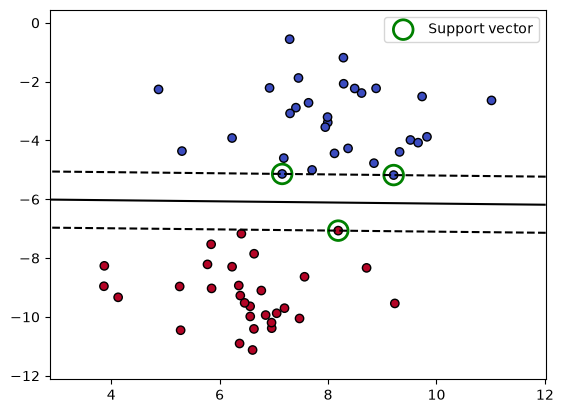

Jumlah support vector: 3 dari 60 data


In [2]:
# hyperplane, margin, dan support vectors pada data dua dimensi
X2, y2 = make_blobs(n_samples=60, centers=2, cluster_std=1.2, random_state=6)
svm2 = SVC(kernel="linear", C=1000).fit(X2, y2)

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 200),
                     np.linspace(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 200))
f = svm2.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", edgecolors="k")
plt.contour(xx, yy, f, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
plt.scatter(*svm2.support_vectors_.T, s=200, facecolors="none", edgecolors="g", linewidths=2, label="Support vector")
plt.legend()
plt.show()
print("Jumlah support vector:", len(svm2.support_vectors_), "dari", len(X2), "data")

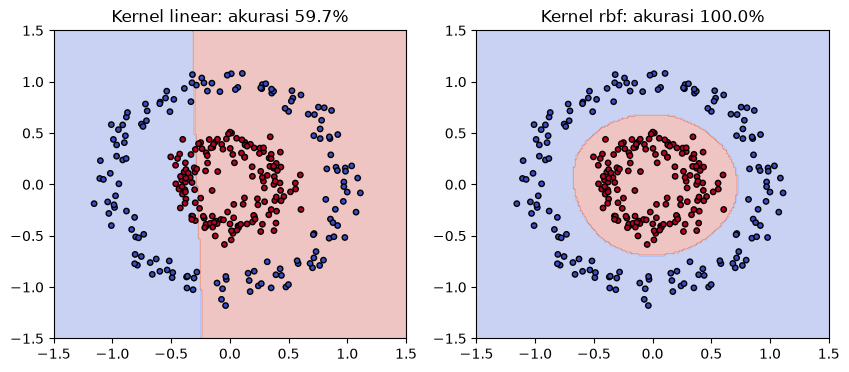

In [3]:
# kernel trick: data lingkaran tidak bisa dipisah garis lurus, tetapi bisa dengan kernel RBF
Xc, yc = make_circles(n_samples=300, factor=0.4, noise=0.08, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, kernel in zip(ax, ["linear", "rbf"]):
    m = SVC(kernel=kernel).fit(Xc, yc)
    gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
    a.contourf(gx, gy, m.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), alpha=0.3, cmap="coolwarm")
    a.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolors="k", s=15)
    a.set_title(f"Kernel {kernel}: akurasi {m.score(Xc, yc):.1%}")
plt.show()

In [4]:
# support vectors pada data KBBI: data yang paling dekat dengan hyperplane
svm = SVC(kernel="linear", C=1).fit(X_train, y_train)
jarak = svm.decision_function(X_train)
is_sv = np.zeros(len(train), dtype=bool)
is_sv[svm.support_] = True

print(f"Support vector: {is_sv.sum():,} dari {len(train):,} data latih ({is_sv.mean():.1%})")
print(f"Rata-rata jarak ke hyperplane, support vector: {np.abs(jarak[is_sv]).mean():.2f} | bukan support vector: {np.abs(jarak[~is_sv]).mean():.2f}")
print(f"Akurasi uji: {accuracy_score(y_test, svm.predict(X_test)):.1%}")

urut = np.argsort(np.abs(jarak))
pd.DataFrame({
    "Jenis": ["Perbatasan"] * 3 + ["Sangat jelas"] * 3,
    "Makna": train["submakna"].iloc[np.r_[urut[:3], urut[-3:]]].str[:60].values,
    "Kelas": y_train.iloc[np.r_[urut[:3], urut[-3:]]].values,
})

Support vector: 2,724 dari 5,000 data latih (54.5%)
Rata-rata jarak ke hyperplane, support vector: 0.71 | bukan support vector: 1.72
Akurasi uji: 85.2%


,Jenis,Makna,Kelas
0,Perbatasan,melakukan kegiatan berjualan sesuatu untuk men...,Verba
1,Perbatasan,berdiri bulu roma,Verba
2,Perbatasan,urai (secara terperinci),Verba
3,Sangat jelas,Duli Yang Mahamulia,Nomina
4,Sangat jelas,hemoglobin yang teroksidasi,Nomina
5,Sangat jelas,yang terkemuka,Nomina


In [5]:
# pengaruh parameter C terhadap lebar margin (C kecil: margin lebar dan toleran, C besar: margin sempit dan ketat)
hasil = []
for c in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="linear", C=c).fit(X_train, y_train)
    lebar = 2 / np.sqrt(m.coef_.multiply(m.coef_).sum())
    hasil.append({"C": c, "Lebar margin": lebar, "Support vector": m.n_support_.sum(),
                  "Akurasi latih": m.score(X_train, y_train), "Akurasi uji": m.score(X_test, y_test)})
pd.DataFrame(hasil).round(3)

,C,Lebar margin,Support vector,Akurasi latih,Akurasi uji
0,0.01,2.207,3380,0.677,0.686
1,0.10,0.234,3364,0.730,0.737
2,1.00,0.061,2724,0.923,0.852
3,10.00,0.032,2172,0.952,0.834
4,100.00,0.025,2010,0.954,0.824


In [6]:
# kernel pada data KBBI
hasil = []
for kernel in ["linear", "poly", "rbf"]:
    t = time.time()
    m = SVC(kernel=kernel).fit(X_train, y_train)
    hasil.append({"Kernel": kernel, "Akurasi uji": m.score(X_test, y_test), "Waktu latih (detik)": time.time() - t})
pd.DataFrame(hasil).round(3)

,Kernel,Akurasi uji,Waktu latih (detik)
0,linear,0.852,1.156
1,poly,0.797,2.193
2,rbf,0.849,2.020


In [7]:
# sulit memilih kernel: grid C dan gamma pada kernel RBF dinilai dengan data validasi dari data latih
X_fit, X_val = X_train[:4000], X_train[4000:]
y_fit, y_val = y_train.iloc[:4000], y_train.iloc[4000:]

grid = pd.DataFrame(index=[0.1, 1, 10], columns=[0.1, 1, 10], dtype=float)
for c in grid.index:
    for g in grid.columns:
        grid.loc[c, g] = SVC(kernel="rbf", C=c, gamma=g).fit(X_fit, y_fit).score(X_val, y_val)
grid.index.name, grid.columns.name = "C", "gamma"
grid.round(3)

gamma,0.1,1.0,10.0
C,,,
0.1,0.685,0.693,0.689
1.0,0.767,0.841,0.710
10.0,0.857,0.855,0.710


In [8]:
# lambat pada data besar: waktu latih naik cepat ketika jumlah data bertambah
hasil = []
for n in [500, 1000, 2000, 4000]:
    t = time.time()
    SVC(kernel="rbf").fit(X_train[:n], y_train.iloc[:n])
    hasil.append({"Jumlah data": n, "Waktu latih (detik)": time.time() - t})
pd.DataFrame(hasil).round(2)

,Jumlah data,Waktu latih (detik)
0,500,0.02
1,1000,0.06
2,2000,0.19
3,4000,0.69


In [9]:
# dimensi tinggi: akurasi SVM linear ketika jumlah fitur (kata) ditambah
hasil = []
for n in [50, 300, 1000, 3000]:
    v = TfidfVectorizer(max_features=n, min_df=2)
    m = LinearSVC().fit(v.fit_transform(train["submakna"]), y_train)
    hasil.append({"Jumlah fitur": n, "Akurasi uji": m.score(v.transform(test["submakna"]), y_test)})
pd.DataFrame(hasil).round(3)

,Jumlah fitur,Akurasi uji
0,50,0.758
1,300,0.801
2,1000,0.820
3,3000,0.849


### Analisis

Pada data dua dimensi, hanya 3 dari 60 titik yang menjadi support vector, yaitu titik yang tepat berada di tepi margin, sedangkan titik lain tidak mempengaruhi posisi hyperplane. Pada data KBBI, support vector rata-rata berjarak 0,71 dari hyperplane dan data lainnya berjarak 1,73, jadi support vector memang data yang paling dekat dengan batas. Namun jumlahnya masih 2.703 dari 5.000 data (54,1 persen) karena makna nomina dan verba banyak yang tumpang tindih, sehingga keuntungan efisiensi memori tidak sebesar pada data yang terpisah jelas.

Parameter C mengatur lebar margin. Pada C 0,01 margin sangat lebar (2,203) tetapi akurasi hanya 68,6 persen karena model terlalu longgar (underfitting). Pada C 100 margin menyempit menjadi 0,021, akurasi latih naik ke 95,5 persen tetapi akurasi uji turun ke 80,9 persen (overfitting). Nilai C 1 memberi akurasi uji terbaik, 85,1 persen. Pada kernel, kernel linear (85,1 persen) setara dengan RBF (84,7 persen) dan lebih baik dari polynomial (79,5 persen), karena data teks dengan 3.000 fitur sudah hampir bisa dipisah garis lurus. Keunggulan kernel RBF terlihat pada data lingkaran, yaitu 100 persen dibanding 59,7 persen untuk kernel linear. Pada grid C dan gamma, gamma yang terlalu besar (10) menurunkan akurasi hingga 71,1 persen, yang menunjukkan bahwa memilih parameter memang butuh percobaan.

Waktu latih naik jauh lebih cepat daripada jumlah data: data bertambah 8 kali (500 ke 4.000) tetapi waktunya naik sekitar 33 kali (0,02 ke 0,66 detik), sehingga SVM menjadi lambat pada data besar. Sebaliknya, makin banyak fitur makin baik: akurasi naik dari 75,8 persen pada 50 fitur menjadi 84,9 persen pada 3.000 fitur, sesuai catatan bahwa SVM bekerja baik pada dimensi tinggi.

In [10]:
# refleksi: data mana yang menjadi support vector?
pd.DataFrame({
    "Data": ["A (BELI VIAGRA PROMO)", "B (newsletter agak promosi)", "C (Tolong kirim laporan)"],
    "Support vector?": ["Bukan", "Ya", "Bukan"],
    "Alasan": ["Jauh dari batas dan sangat jelas spam", "Paling dekat dengan batas kedua kelas", "Jauh dari batas dan sangat jelas penting"],
})

,Data,Support vector?,Alasan
0,A (BELI VIAGRA PROMO),Bukan,Jauh dari batas dan sangat jelas spam
1,B (newsletter agak promosi),Ya,Paling dekat dengan batas kedua kelas
2,C (Tolong kirim laporan),Bukan,Jauh dari batas dan sangat jelas penting
